In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import dcor
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

1. Load the data

In [2]:
# scikit-learn Diabetes dataset (Efron et al. 2004)
diabetes = load_diabetes(as_frame=True)

# data (as pandas dataframes)
df = diabetes.frame.copy()

# metadata / description
print(diabetes.DESCR[:1300])

.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6      glu, blood sugar level

Note: Each of these 10 feature variables have bee

2. Data preparation and cleaning

In [ ]:
# Target and predictor roles
TARGET = "target"
feature_cols = [c for c in df.columns if c != TARGET]

# The 10 predictors are documented as mean-centered and L2-scaled by the authors.
print(f"Total dimensions of the table: {df.shape}")
print(f"Number of predictors: {len(feature_cols)}")
print(f"Predictors: {feature_cols}")
print(f"Target: {TARGET} (quantitative disease progression one year after baseline)")

Total dimensions of the table: (442, 11)
Number of predictors: 10
Predictors: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
Target: target (quantitative disease progression one year after baseline)


3. EDA & Diagnostics

In [4]:
# Missing values, duplicates, constant columns
print(f"Total missing cells: {int(df.isna().sum().sum())}")
print(f"Rows with >=1 missing value: {int((df.isna().sum(axis=1) > 0).sum())}")
print(f"Full duplicate rows: {int(df.duplicated().sum())}")
print(f"Constant columns: {[c for c in df.columns if df[c].nunique() <= 1]}")

# Confirm the documented standardization (mean ~0, sum of squares = 1)
std_check = pd.DataFrame({
    "mean": df[feature_cols].mean(),
    "std": df[feature_cols].std(),
    "sum_of_squares": (df[feature_cols] ** 2).sum(),
    "min": df[feature_cols].min(),
    "max": df[feature_cols].max(),
}).round(4)
print("\nStandardization check (first rows):")
print(std_check.head().to_string())

Total missing cells: 0
Rows with >=1 missing value: 0
Full duplicate rows: 0
Constant columns: []

Standardization check (first rows):
     mean     std  sum_of_squares     min     max
age  -0.0  0.0476             1.0 -0.1072  0.1107
sex   0.0  0.0476             1.0 -0.0446  0.0507
bmi  -0.0  0.0476             1.0 -0.0903  0.1706
bp   -0.0  0.0476             1.0 -0.1124  0.1320
s1   -0.0  0.0476             1.0 -0.1268  0.1539


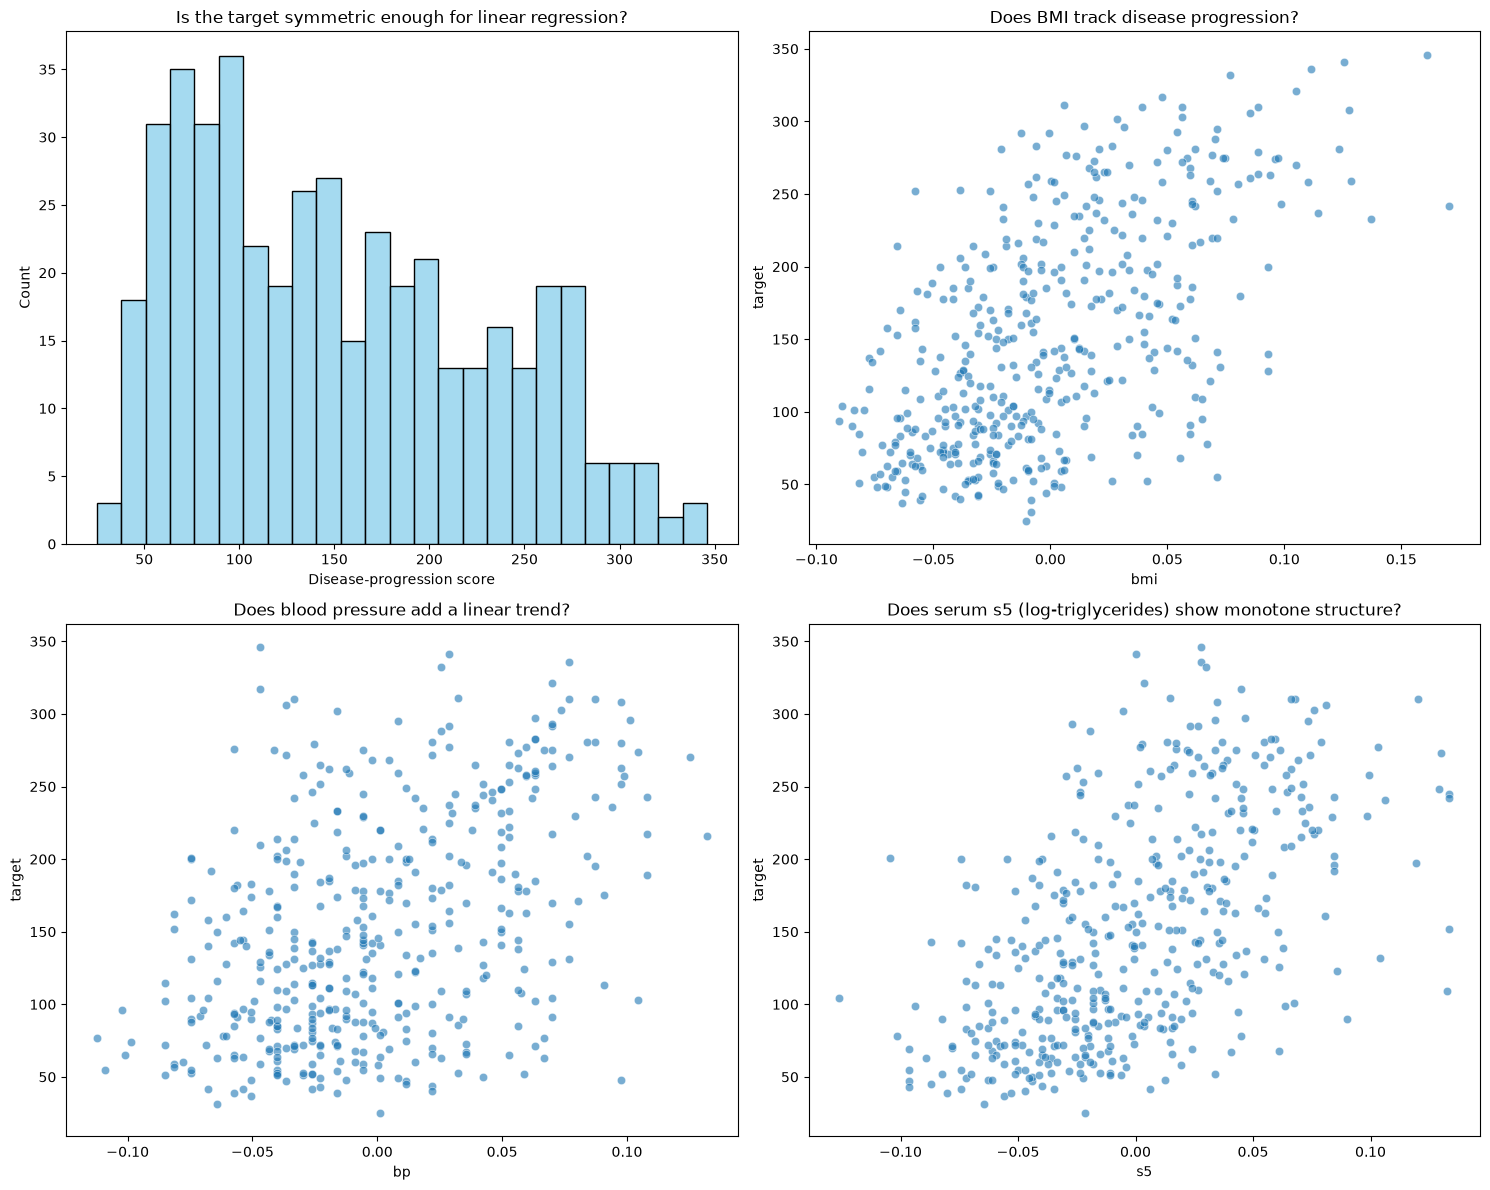

In [5]:
import os
os.makedirs('plots', exist_ok=True)
os.makedirs('outputs', exist_ok=True)

# EDA panel: target distribution + three predictor-target relationships
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# Graph 1: Is the target roughly symmetric / continuous?
sns.histplot(df[TARGET], bins=25, ax=axes[0, 0], color='skyblue')
axes[0, 0].set_title('Is the target symmetric enough for linear regression?')
axes[0, 0].set_xlabel('Disease-progression score')

# Graph 2: bmi vs target (strongest a-priori driver)
sns.scatterplot(data=df, x='bmi', y=TARGET, ax=axes[0, 1], alpha=0.6)
axes[0, 1].set_title('Does BMI track disease progression?')

# Graph 3: bp vs target
sns.scatterplot(data=df, x='bp', y=TARGET, ax=axes[1, 0], alpha=0.6)
axes[1, 0].set_title('Does blood pressure add a linear trend?')

# Graph 4: s5 vs target
sns.scatterplot(data=df, x='s5', y=TARGET, ax=axes[1, 1], alpha=0.6)
axes[1, 1].set_title('Does serum s5 (log-triglycerides) show monotone structure?')

plt.tight_layout()
plt.savefig('plots/01_eda_panel.png', dpi=120, bbox_inches='tight')
plt.show()

4. Correlation (Pearson, Spearman, distance correlation)

In [ ]:
pearson = df.corr(method='pearson')[TARGET].drop(TARGET)
spearman = df.corr(method='spearman')[TARGET].drop(TARGET)
dcor_values = {f: dcor.distance_correlation(df[f].to_numpy(), df[TARGET].to_numpy())
               for f in feature_cols}

corr_table = pd.DataFrame({
    'Pearson': pearson,
    'Spearman': spearman,
    'Distance correlation': pd.Series(dcor_values),
}).sort_values('Pearson', key=lambda s: s.abs(), ascending=False).round(3)

corr_table.to_csv('outputs/correlation_table.csv')
strongest = corr_table['Pearson'].abs().idxmax()
print(f"Most strongly (Pearson) correlated predictor with target: {strongest} "
      f"=> {corr_table.loc[strongest, 'Pearson']}")
print(corr_table.to_string())

Most strongly (Pearson) correlated predictor with target: bmi => 0.586
     Pearson  Spearman  Distance correlation
bmi    0.586     0.561                 0.548
s5     0.566     0.589                 0.565
bp     0.441     0.416                 0.424
s4     0.430     0.449                 0.422
s3    -0.395    -0.410                 0.390
s6     0.382     0.351                 0.350
s1     0.212     0.232                 0.227
age    0.188     0.198                 0.187
s2     0.174     0.196                 0.193
sex    0.043     0.037                 0.048


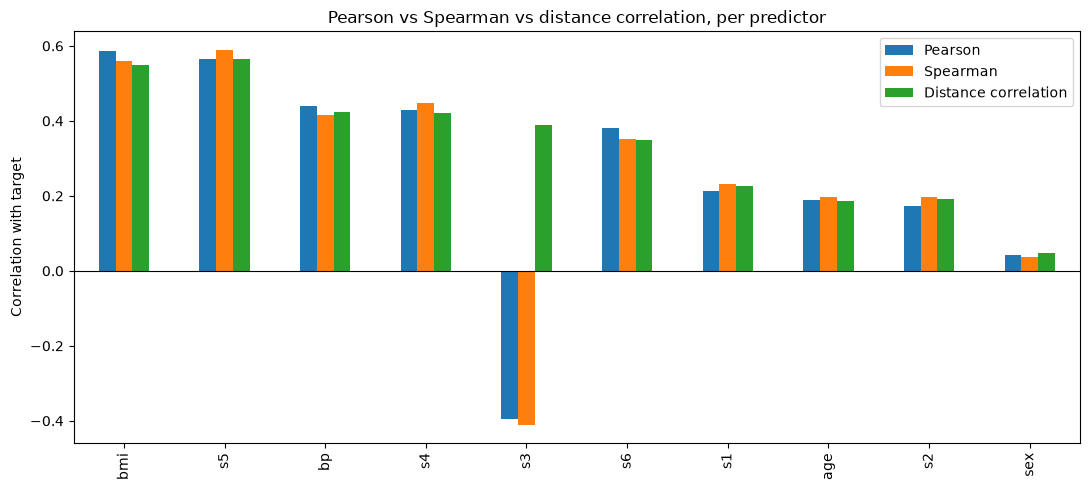

In [7]:
# Visualize the three measures side by side
plot_tbl = corr_table.copy()
plot_tbl.plot(kind='bar', figsize=(11, 5))
plt.ylabel('Correlation with target')
plt.title('Pearson vs Spearman vs distance correlation, per predictor')
plt.axhline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.savefig('plots/02_correlation_measures.png', dpi=120, bbox_inches='tight')
plt.show()

5. Simple linear regression (bmi -> target)

Predictor: bmi
Intercept (beta_0): 152.13
Slope (beta_1): 949.44


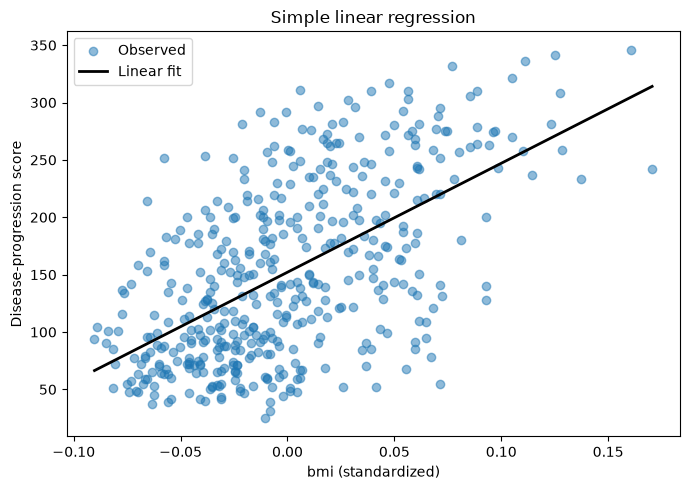

In [8]:
x_simple = strongest  # 'bmi'
X_s = df[[x_simple]]
y = df[TARGET]

simple_model = LinearRegression().fit(X_s, y)
print(f"Predictor: {x_simple}")
print(f"Intercept (beta_0): {simple_model.intercept_:.2f}")
print(f"Slope (beta_1): {simple_model.coef_[0]:.2f}")

# Fitted line
y_hat_s = simple_model.predict(X_s)
order = np.argsort(X_s[x_simple].to_numpy())
plt.figure(figsize=(7, 5))
plt.scatter(X_s[x_simple], y, alpha=0.5, label='Observed')
plt.plot(X_s[x_simple].to_numpy()[order], y_hat_s[order],
         color='black', linewidth=2, label='Linear fit')
plt.xlabel(f'{x_simple} (standardized)')
plt.ylabel('Disease-progression score')
plt.title('Simple linear regression')
plt.legend()
plt.tight_layout()
plt.savefig('plots/03_simple_regression.png', dpi=120, bbox_inches='tight')
plt.show()

6. Residual diagnostics

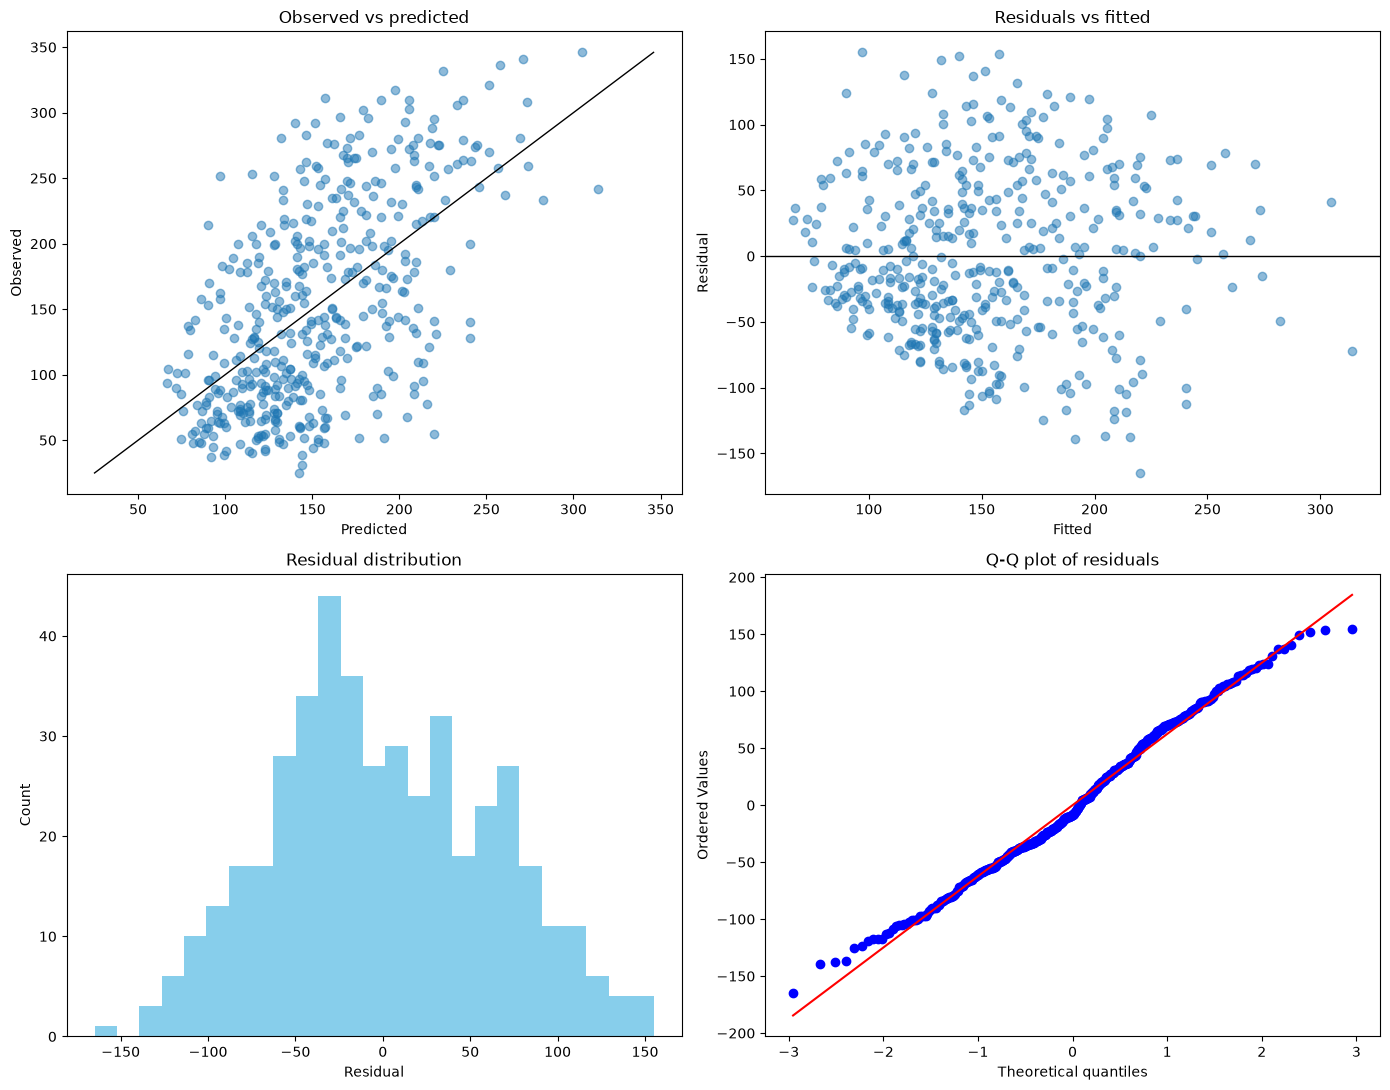

In [9]:
residuals = y.to_numpy() - y_hat_s

fig, axes = plt.subplots(2, 2, figsize=(14, 11))

# Observed vs predicted
axes[0, 0].scatter(y_hat_s, y, alpha=0.5)
lims = [min(y.min(), y_hat_s.min()), max(y.max(), y_hat_s.max())]
axes[0, 0].plot(lims, lims, color='black', linewidth=1)
axes[0, 0].set_xlabel('Predicted'); axes[0, 0].set_ylabel('Observed')
axes[0, 0].set_title('Observed vs predicted')

# Residuals vs fitted
axes[0, 1].scatter(y_hat_s, residuals, alpha=0.5)
axes[0, 1].axhline(0, color='black', linewidth=1)
axes[0, 1].set_xlabel('Fitted'); axes[0, 1].set_ylabel('Residual')
axes[0, 1].set_title('Residuals vs fitted')

# Residual histogram
axes[1, 0].hist(residuals, bins=25, color='skyblue')
axes[1, 0].set_xlabel('Residual'); axes[1, 0].set_ylabel('Count')
axes[1, 0].set_title('Residual distribution')

# Q-Q plot
stats.probplot(residuals, dist='norm', plot=axes[1, 1])
axes[1, 1].set_title('Q-Q plot of residuals')

plt.tight_layout()
plt.savefig('plots/04_residual_diagnostics.png', dpi=120, bbox_inches='tight')
plt.show()

7. Multiple regression and multicollinearity

In [10]:
X_full = df[feature_cols]
multiple_model = LinearRegression().fit(X_full, y)

coef_table = pd.DataFrame({'feature': feature_cols, 'coefficient': multiple_model.coef_}) \
    .sort_values('coefficient', key=lambda s: s.abs(), ascending=False)
coef_table.to_csv('outputs/coefficients_multiple.csv', index=False)
print(f"Intercept: {multiple_model.intercept_:.2f}")
print(coef_table.round(2).to_string(index=False))

Intercept: 152.13
feature  coefficient
     s1      -792.18
     s5       751.27
    bmi       519.85
     s2       476.74
     bp       324.38
    sex      -239.82
     s4       177.06
     s3       101.04
     s6        67.63
    age       -10.01


Variance Inflation Factors:
s1     59.20
s2     39.19
s3     15.40
s5     10.08
s4      8.89
bmi     1.51
s6      1.48
bp      1.46
sex     1.28
age     1.22


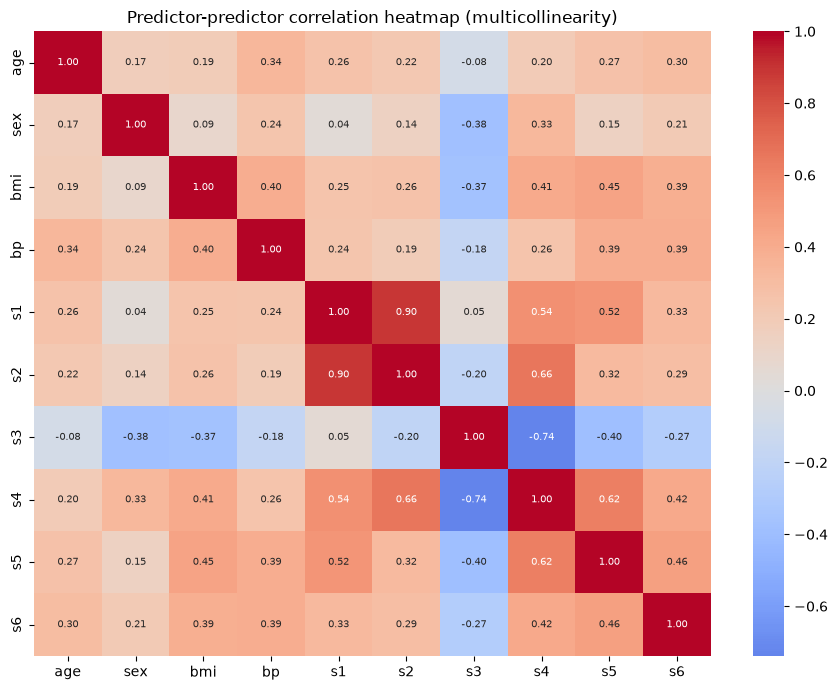

In [11]:
# Variance Inflation Factor as a multicollinearity summary
def vif(frame):
    out = {}
    cols = frame.columns.tolist()
    for c in cols:
        others = [k for k in cols if k != c]
        r2 = LinearRegression().fit(frame[others], frame[c]).score(frame[others], frame[c])
        out[c] = np.inf if r2 >= 1 else 1.0 / (1.0 - r2)
    return pd.Series(out, name='VIF').sort_values(ascending=False)

vif_series = vif(X_full)
vif_series.to_frame().to_csv('outputs/vif.csv')
print("Variance Inflation Factors:")
print(vif_series.round(2).to_string())

# Predictor-predictor correlation heatmap
plt.figure(figsize=(9, 7))
sns.heatmap(X_full.corr(), cmap='coolwarm', center=0, annot=True, fmt='.2f',
            annot_kws={'size': 7})
plt.title('Predictor-predictor correlation heatmap (multicollinearity)')
plt.tight_layout()
plt.savefig('plots/05_multicollinearity_heatmap.png', dpi=120, bbox_inches='tight')
plt.show()

8. Train/test evaluation

In [12]:
RANDOM_STATE = 42
X_train, X_test, y_train, y_test = train_test_split(
    df[feature_cols], y, test_size=0.2, random_state=RANDOM_STATE)

def regression_metrics(y_true, y_pred):
    return {
        'MAE': mean_absolute_error(y_true, y_pred),
        'MSE': mean_squared_error(y_true, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
        'R2': r2_score(y_true, y_pred),
    }

results = []
# Simple model: bmi only
m1 = LinearRegression().fit(X_train[[x_simple]], y_train)
for name, Xs, ys in [('train', X_train, y_train), ('test', X_test, y_test)]:
    results.append({'model': 'Simple (bmi)', 'split': name,
                    **regression_metrics(ys, m1.predict(Xs[[x_simple]]))})

# Multiple model: all 10 predictors
m2 = LinearRegression().fit(X_train, y_train)
for name, Xs, ys in [('train', X_train, y_train), ('test', X_test, y_test)]:
    results.append({'model': 'Multiple (all 10)', 'split': name,
                    **regression_metrics(ys, m2.predict(Xs))})

results_df = pd.DataFrame(results).round(3)
results_df.to_csv('outputs/metrics_train_test.csv', index=False)
print(results_df.to_string(index=False))
print("\nHeld-out (test) performance, best RMSE first:")
print(results_df[results_df['split'] == 'test'].sort_values('RMSE').to_string(index=False))

            model split    MAE      MSE   RMSE    R2
     Simple (bmi) train 51.380 3854.113 62.082 0.366
     Simple (bmi)  test 52.260 4061.826 63.732 0.233
Multiple (all 10) train 43.484 2868.550 53.559 0.528
Multiple (all 10)  test 42.794 2900.194 53.853 0.453

Held-out (test) performance, best RMSE first:
            model split    MAE      MSE   RMSE    R2
Multiple (all 10)  test 42.794 2900.194 53.853 0.453
     Simple (bmi)  test 52.260 4061.826 63.732 0.233


9. Deliverable: save the ML-ready split

In [13]:
X_train.to_csv('outputs/X_train.csv')
X_test.to_csv('outputs/X_test.csv')
y_train.to_frame('target').to_csv('outputs/y_train.csv')
y_test.to_frame('target').to_csv('outputs/y_test.csv')
print("Saved ->", sorted(os.listdir('outputs')))

Saved -> ['X_test.csv', 'X_train.csv', 'coefficients_multiple.csv', 'correlation_table.csv', 'metrics_train_test.csv', 'vif.csv', 'y_test.csv', 'y_train.csv']


10. Reproducibility

In [14]:
import sys, sklearn, scipy
np.random.seed(RANDOM_STATE)
print("Python      :", sys.version.split()[0])
print("pandas      :", pd.__version__)
print("numpy       :", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("scipy       :", scipy.__version__)
print("seaborn     :", sns.__version__)
print("dcor        :", dcor.__version__)
print("RANDOM_STATE:", RANDOM_STATE)
print("Shapes -> X_train:", X_train.shape, "X_test:", X_test.shape)

Python      : 3.11.16
pandas      : 3.0.5
numpy       : 2.4.6
scikit-learn: 1.9.0
scipy       : 1.17.1
seaborn     : 0.13.2
dcor        : 0.7
RANDOM_STATE: 42
Shapes -> X_train: (353, 10) X_test: (89, 10)
